In [2]:
import rioxarray as rxr
import xarray as xr

# Open the NetCDF
ds = xr.open_dataset("GDP_per_capita_PPP_1990_2015_v2.nc")
print(ds)          # inspect variables, dimensions, coordinates
print(ds.data_vars) # see which variable(s) you want to export

<xarray.Dataset> Size: 970MB
Dimensions:             (time: 26, latitude: 2160, longitude: 4320)
Coordinates:
  * time                (time) float32 104B 1.99e+03 1.991e+03 ... 2.015e+03
  * latitude            (latitude) float32 9kB 89.96 89.88 ... -89.88 -89.96
  * longitude           (longitude) float32 17kB -180.0 -179.9 ... 179.9 180.0
Data variables:
    GDP_per_capita_PPP  (time, latitude, longitude) float32 970MB ...
Attributes:
    creation_date:     02-Aug-2017 14:29:40
    resolution:        5 arc-min
    projection:        WGS84
    extent:            lat: 90�S - 90�N; lon: 180�E - 180�W
    product:           Gross Domestic Production (GDP) per capita (PPP) for y...
    citation:          When using the data, please refer to following publica...
    more information:  For more information, see: TBA
Data variables:
    GDP_per_capita_PPP  (time, latitude, longitude) float32 970MB ...


In [3]:
import rioxarray as rxr
import xarray as xr

ds = xr.open_dataset("GDP_per_capita_PPP_1990_2015_v2.nc")

# Time is stored as decimal years (float), not datetime — select by nearest value
da_2015 = ds["GDP_per_capita_PPP"].sel(time=2015, method="nearest")

# Tell rioxarray which dims are spatial (usually auto-detected, but explicit is safer here)
da_2015 = da_2015.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude")
da_2015 = da_2015.rio.write_crs("EPSG:4326", inplace=True)

da_2015.rio.to_raster("GDP_PPP_2015.tif")

In [4]:
print(da_2015.time.values)   # should print ~2015.0

2015.0


In [ ]:
# Converting all 26 years into one multi-band GeoTIFF
#If you want every year as a separate band (like your existing GDP_PPP_2015.tif band-3-is-2015 setup):

In [5]:
da_all = ds["GDP_per_capita_PPP"]
da_all = da_all.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude")
da_all = da_all.rio.write_crs("EPSG:4326", inplace=True)

da_all.rio.to_raster("GDP_PPP_1990_2015_allyears.tif")

In [13]:
import rioxarray as rxr
import xarray as xr
import os
import geopandas as gpd

# --- 1. Load the NetCDF and select 2015 ---
ROOT_DIR = os.path.abspath(os.curdir)
ds = xr.open_dataset("GDP_per_capita_PPP_1990_2015_v2.nc")

da_2015 = ds["GDP_per_capita_PPP"].sel(time=2015, method="nearest")
print("Selected time:", da_2015.time.values)   # sanity check — should print ~2015.0

# --- 2. Tell rioxarray the spatial dims + CRS ---
da_2015 = da_2015.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude")
da_2015 = da_2015.rio.write_crs("EPSG:4326", inplace=True)

# --- 3. Load Malawi's boundary (same shapefile your notebook already uses) ---
mask_path = ROOT_DIR + "\\" + 'admin'
mask_name = 'gadm36_MWI_0.shp'
malawi_gdf = gpd.read_file(mask_path + "\\" + mask_name)

# --- 4. Clip to Malawi ---
da_mw_2015 = da_2015.rio.clip(malawi_gdf.geometry, malawi_gdf.crs, drop=True)

# --- 5. Export to GeoTIFF ---
gdp_path = ROOT_DIR + "\\" + 'GDP_data'
out_file = gdp_path + "\\" + "GDP_PPP_2015_malawi1.tif"
da_mw_2015.rio.to_raster(out_file)

print("Written:", out_file)

Selected time: 2015.0
Written: C:\Users\Bachirou\Documents\CREDIT_layer\GDP_data\GDP_PPP_2015_malawi1.tif


CRS: EPSG:4326
Shape: (93, 39)
Bounds: BoundingBox(left=32.666661513479134, bottom=-17.1666666528453, right=35.916666733591185, top=-9.416669223619545)


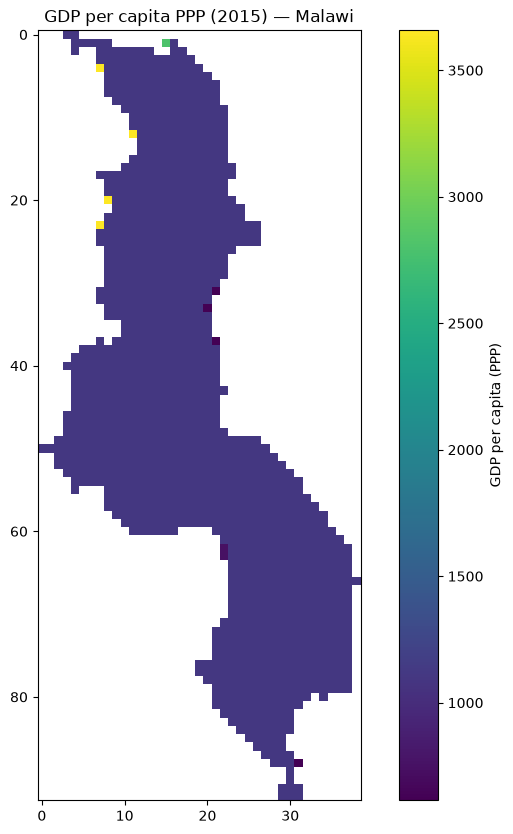

In [10]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np

with rasterio.open(out_file) as src:
    arr = src.read(1)
    print("CRS:", src.crs)
    print("Shape:", arr.shape)
    print("Bounds:", src.bounds)

plt.figure(figsize=(10, 10))
plt.imshow(np.ma.masked_equal(arr, arr[0, 0]), cmap="viridis")  # mask nodata border if present
plt.title("GDP per capita PPP (2015) — Malawi")
plt.colorbar(label="GDP per capita (PPP)")
plt.show()

CRS: None
Shape: (1107, 1460)
Bounds: BoundingBox(left=28.35000016, bottom=-17.816666868, right=40.516666896, top=-8.591666764)


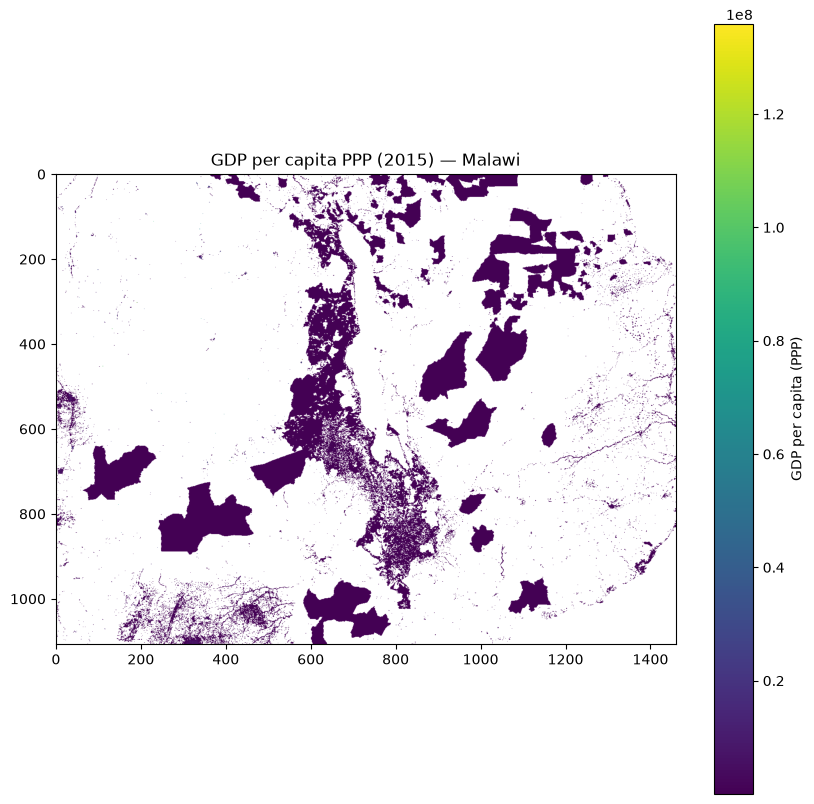

In [11]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np
gdp_path = ROOT_DIR + "\\" + 'GDP_data'
out_file = gdp_path + "\\" + "GDP_PPP_2015.tif"
with rasterio.open(out_file) as src:
    arr = src.read(1)
    print("CRS:", src.crs)
    print("Shape:", arr.shape)
    print("Bounds:", src.bounds)

plt.figure(figsize=(10, 10))
plt.imshow(np.ma.masked_equal(arr, arr[0, 0]), cmap="viridis")  # mask nodata border if present
plt.title("GDP per capita PPP (2015) — Malawi")
plt.colorbar(label="GDP per capita (PPP)")
plt.show()

In [13]:
import rioxarray as rxr
import xarray as xr
import geopandas as gpd

# --- 1. Load the NetCDF and select 2015 ---
ds = xr.open_dataset("GDP_per_capita_PPP_1990_2015_v2.nc")

da_2015 = ds["GDP_per_capita_PPP"].sel(time=2015, method="nearest")
print("Selected time:", da_2015.time.values)   # sanity check — should print ~2015.0

# --- 2. Tell rioxarray the spatial dims + CRS ---
da_2015 = da_2015.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude")
da_2015 = da_2015.rio.write_crs("EPSG:4326", inplace=True)

# --- 3. Load Malawi's boundary (same shapefile your notebook already uses) ---
mask_path = ROOT_DIR + "\\" + 'admin'
mask_name = 'gadm36_MWI_0.shp'
malawi_gdf = gpd.read_file(mask_path + "\\" + mask_name)

# --- 4. Clip to Malawi ---
da_mw_2015 = da_2015.rio.clip(malawi_gdf.geometry, malawi_gdf.crs, drop=True)

# --- 5. Export to GeoTIFF ---
gdp_path = ROOT_DIR + "\\" + 'GDP_data'
out_file = gdp_path + "\\" + "GDP_PPP_2015_malawi.tif"
da_mw_2015.rio.to_raster(out_file)

print("Written:", out_file)

Selected time: 2015.0
Written: C:\Users\Bachirou\Documents\CREDIT_layer\GDP_data\GDP_PPP_2015_malawi.tif


CRS: EPSG:4326
Shape: (93, 39)
Bounds: BoundingBox(left=32.666661513479134, bottom=-17.1666666528453, right=35.916666733591185, top=-9.416669223619545)


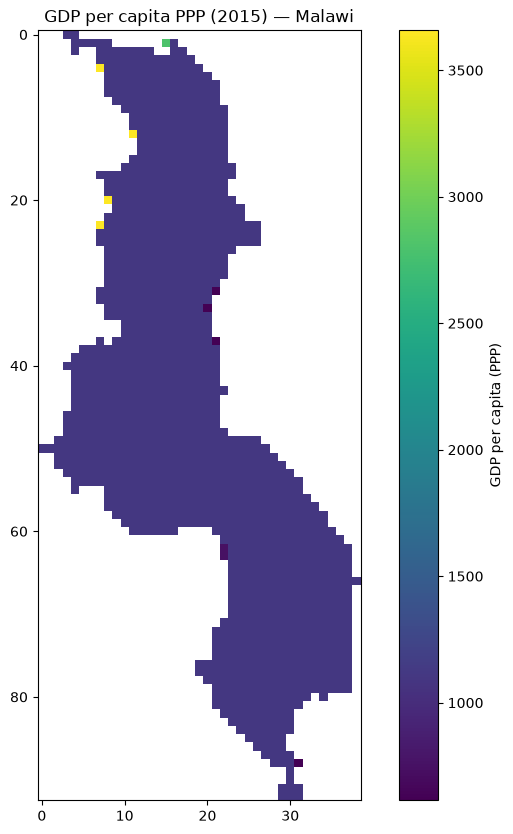

In [14]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np

with rasterio.open(out_file) as src:
    arr = src.read(1)
    print("CRS:", src.crs)
    print("Shape:", arr.shape)
    print("Bounds:", src.bounds)

plt.figure(figsize=(10, 10))
plt.imshow(np.ma.masked_equal(arr, arr[0, 0]), cmap="viridis")  # mask nodata border if present
plt.title("GDP per capita PPP (2015) — Malawi")
plt.colorbar(label="GDP per capita (PPP)")
plt.show()

In [15]:
print(da_mw_2015.rio.nodata)

None


In [16]:
import rioxarray as rxr
import xarray as xr
import geopandas as gpd

# --- 1. Load the NetCDF and select 2015 ---
ds = xr.open_dataset("GDP_per_capita_PPP_1990_2015_v2.nc")

da_2015 = ds["GDP_per_capita_PPP"].sel(time=2015, method="nearest")
print("Selected time:", da_2015.time.values)   # should print ~2015.0

# --- 2. Spatial dims + CRS ---
da_2015 = da_2015.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude")
da_2015 = da_2015.rio.write_crs("EPSG:4326", inplace=True)

# --- 3. Malawi boundary (reuse the same shapefile your notebook already loads) ---
mask_path = ROOT_DIR + "\\" + 'admin'
mask_name = 'gadm36_MWI_0.shp'
malawi_gdf = gpd.read_file(mask_path + "\\" + mask_name)

# --- 4. Clip ---
da_mw_2015 = da_2015.rio.clip(malawi_gdf.geometry, malawi_gdf.crs, drop=True)

# --- 5. Export ---
gdp_path = ROOT_DIR + "\\" + 'GDP_data'
out_file = gdp_path + "\\" + "GDP_PPP_2015_malawi.tif"
da_mw_2015.rio.to_raster(out_file)

print("Written:", out_file)

Selected time: 2015.0
Written: C:\Users\Bachirou\Documents\CREDIT_layer\GDP_data\GDP_PPP_2015_malawi.tif


In [17]:
import rioxarray as rxr
import xarray as xr
import geopandas as gpd

# --- 1. Load the NetCDF and select 2015 ---
ds = xr.open_dataset("GDP_per_capita_PPP_1990_2015_v2.nc")

da_2015 = ds["GDP_per_capita_PPP"].sel(time=2015, method="nearest")
print("Selected time:", da_2015.time.values)   # should print ~2015.0

# --- 2. Spatial dims + CRS ---
da_2015 = da_2015.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude")
da_2015 = da_2015.rio.write_crs("EPSG:4326", inplace=True)

# --- 3. Malawi boundary (reuse the same shapefile your notebook already loads) ---
mask_path = ROOT_DIR + "\\" + 'admin'
mask_name = 'gadm36_MWI_0.shp'
malawi_gdf = gpd.read_file(mask_path + "\\" + mask_name)

# --- 4. Clip ---
da_mw_2015 = da_2015.rio.clip(malawi_gdf.geometry, malawi_gdf.crs, drop=True)

# --- 5. Export ---
gdp_path = ROOT_DIR + "\\" + 'GDP_data'
out_file = gdp_path + "\\" + "GDP_PPP_2015_malawi.tif"
da_mw_2015.rio.to_raster(out_file)

print("Written:", out_file)

Selected time: 2015.0
Written: C:\Users\Bachirou\Documents\CREDIT_layer\GDP_data\GDP_PPP_2015_malawi.tif


In [ ]:
"""
Makes sense — rather than one-off code, you want a reusable function that replicates whatever preprocessing produced your existing GDP_PPP_2015.tif, so you can regenerate it (or generate other years/countries) directly from the raw Kummu et al. .nc source on demand.

Here's a general-purpose preprocessing function for this dataset:
""""

In [18]:
import xarray as xr
import rioxarray as rxr
import geopandas as gpd
import rasterio
import numpy as np


def preprocess_kummu_gdp(nc_path, year, boundary_gdf=None, out_path=None,
                          variable="GDP_per_capita_PPP", nodata_value=-9999):
    """
    Preprocess a Kummu et al. (2018) gridded GDP NetCDF into a single-year,
    optionally country-clipped GeoTIFF.

    Parameters
    ----------
    nc_path : str
        Path to the source .nc file (e.g. GDP_per_capita_PPP_1990_2015_v2.nc)
    year : int or float
        Target year (1990-2015). Nearest available time step is used.
    boundary_gdf : geopandas.GeoDataFrame, optional
        Country/admin boundary to clip to. If None, no clipping is applied
        (full global extent is written).
    out_path : str
        Output .tif path.
    variable : str
        Name of the data variable in the NetCDF (default matches this dataset).
    nodata_value : float
        Nodata value to assign to the output raster.

    Returns
    -------
    str : path to the written GeoTIFF
    """
    # --- Open and select year ---
    ds = xr.open_dataset(nc_path)
    if variable not in ds.data_vars:
        raise ValueError(f"Variable '{variable}' not found. Available: {list(ds.data_vars)}")

    da = ds[variable].sel(time=year, method="nearest")
    actual_year = float(da.time.values)
    if abs(actual_year - year) > 0.5:
        print(f"Warning: requested year {year}, nearest available is {actual_year}")

    # --- Set spatial dims + CRS ---
    da = da.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude")
    da = da.rio.write_crs("EPSG:4326", inplace=True)
    da = da.rio.write_nodata(nodata_value)

    # --- Clip if a boundary was provided ---
    if boundary_gdf is not None:
        if boundary_gdf.crs != da.rio.crs:
            boundary_gdf = boundary_gdf.to_crs(da.rio.crs)
        da = da.rio.clip(boundary_gdf.geometry, boundary_gdf.crs, drop=True)

    # --- Write ---
    if out_path is None:
        raise ValueError("out_path must be provided")
    da.rio.to_raster(out_path)

    print(f"Written {out_path} | year={actual_year} | shape={da.shape} | crs={da.rio.crs}")
    return out_path

In [28]:
mask_path = ROOT_DIR + "\\" + 'admin'
mask_name = 'gadm36_MWI_0.shp'
malawi_gdf = gpd.read_file(mask_path + "\\" + mask_name)

gdp_path = ROOT_DIR + "\\" + 'GDP_data'
nc_file = gdp_path + "\\" + "GDP_per_capita_PPP_1990_2015_v2.nc"

preprocess_kummu_gdp(
    nc_path=nc_file,
    year=2015,
    boundary_gdf=malawi_gdf,
    out_path=gdp_path + "\\" + "GDP_PPP_2015v2.tif"
)

Written C:\Users\Bachirou\Documents\CREDIT_layer\GDP_data\GDP_PPP_2015v2.tif | year=2015.0 | shape=(93, 39) | crs=EPSG:4326


'C:\\Users\\Bachirou\\Documents\\CREDIT_layer\\GDP_data\\GDP_PPP_2015v2.tif'

In [21]:
import rasterio
import numpy as np

original_file = gdp_path + "\\" + "GDP_PPP_2015.tif"
regenerated_file = gdp_path + "\\" + "GDP_PPP_2015v2.tif"

with rasterio.open(original_file) as a, rasterio.open(regenerated_file) as b:
    print("CRS match:   ", a.crs == b.crs)
    print("Shape match: ", a.shape == b.shape, "|", a.shape, "vs", b.shape)
    print("Bounds match:", a.bounds == b.bounds)
    print("Res match:   ", a.res == b.res)
    print("Nodata:      ", a.nodata, "vs", b.nodata)

    if a.shape == b.shape:
        arr_a = a.read(1).astype(float)
        arr_b = b.read(1).astype(float)
        diff = arr_a - arr_b
        print("Max abs difference:", np.nanmax(np.abs(diff)))
        print("Mean abs difference:", np.nanmean(np.abs(diff)))
    else:
        print("Shapes differ — can't do a direct pixel diff. Compare via overlapping extent/resample instead.")

CRS match:    False
Shape match:  False | (1107, 1460) vs (93, 39)
Bounds match: False
Res match:    False
Nodata:       -9.0 vs -9999.0
Shapes differ — can't do a direct pixel diff. Compare via overlapping extent/resample instead.


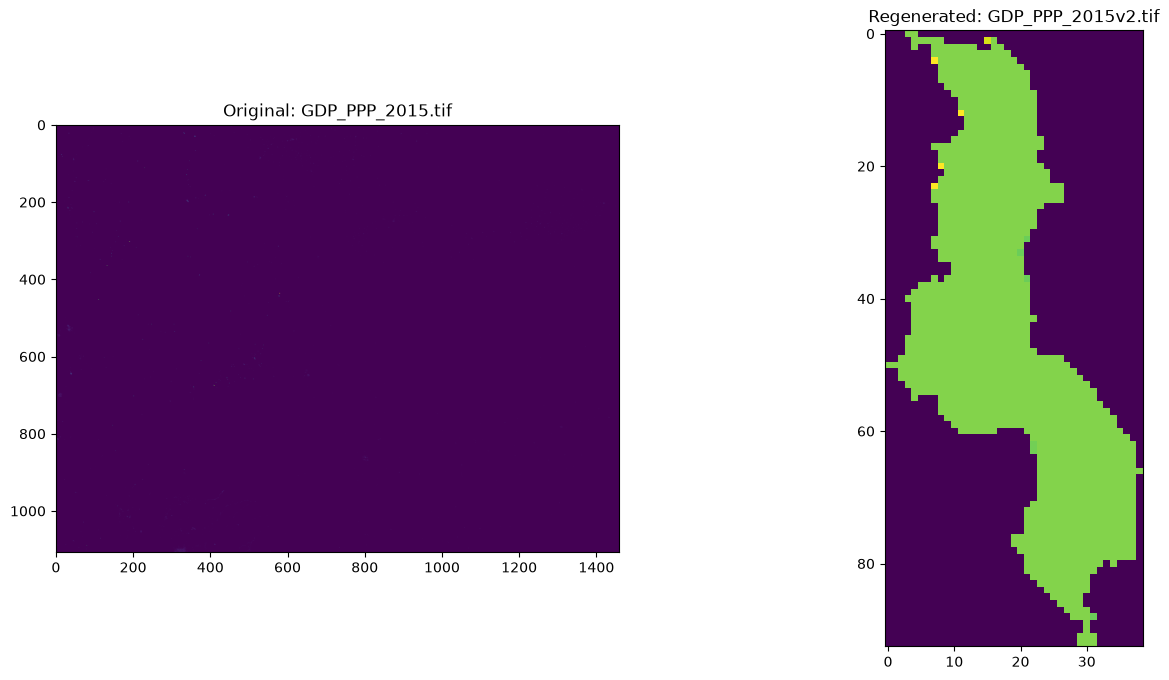

In [22]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

with rasterio.open(original_file) as a:
    axes[0].imshow(a.read(1), cmap="viridis")
    axes[0].set_title("Original: GDP_PPP_2015.tif")

with rasterio.open(regenerated_file) as b:
    axes[1].imshow(b.read(1), cmap="viridis")
    axes[1].set_title("Regenerated: GDP_PPP_2015v2.tif")

plt.show()

In [24]:
with rasterio.open(original_file) as a:
    print("Resolution (deg/pixel):", a.res)
    print("Bounds:", a.bounds)
    print("CRS:", a.crs)

with rasterio.open(regenerated_file) as b:
    print("Resolution (deg/pixel):", b.res)
    print("Bounds:", b.bounds)
    print("CRS:", b.crs)

Resolution (deg/pixel): (0.008333333380821916, 0.008333333427280938)
Bounds: BoundingBox(left=32.66666685126575, bottom=-17.13333352696296, right=35.9166668697863, top=-9.358333439309845)
CRS: None
Resolution (deg/pixel): (0.08333346718236019, 0.08333330569059952)
Bounds: BoundingBox(left=32.666661513479134, bottom=-17.1666666528453, right=35.916666733591185, top=-9.416669223619545)
CRS: EPSG:4326


In [25]:
with rasterio.open(original_file) as a:
    arr = a.read(1)
    valid = arr[arr != a.nodata] if a.nodata is not None else arr[~np.isnan(arr)]
    print("Min:", valid.min())
    print("Max:", valid.max())
    print("Mean:", valid.mean())

Min: 5.5766935
Max: 19511720.0
Mean: 109584.695


In [30]:
gdp_path

'C:\\Users\\Bachirou\\Documents\\CREDIT_layer\\GDP_data'

In [32]:
import xarray as xr
import rioxarray as rxr

nc_file_total_gdp = gdp_path + "\\" + "GDP_PPP_30arcsec_v3.nc"   # or _v3.nc if that's what you have

ds = xr.open_dataset(nc_file_total_gdp)
print(ds.data_vars)   # confirm the exact variable name before proceeding

da = ds["GDP_PPP"].sel(time=2015, method="nearest")   # adjust variable name if print() shows otherwise
print("Selected time:", da.time.values)

da = da.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude")
da = da.rio.write_crs("EPSG:4326", inplace=True)
da = da.rio.write_nodata(-9999)

da_mw = da.rio.clip(malawi_gdf.geometry, malawi_gdf.crs, drop=True)
da_mw.rio.to_raster(gdp_path + "\\" + "GDP_PPP_2015v2.tif")

Data variables:
    GDP_PPP  (time, latitude, longitude) float32 11GB ...
Selected time: 2015.0


In [ ]:
preprocess_kummu_gdp(
    nc_path=nc_file_total_gdp,
    year=2015,
    boundary_gdf=malawi_gdf,
    variable="GDP_PPP",   # confirm exact name from ds.data_vars
    out_path=gdp_path + "\\" + "GDP_PPP_2015v2.tif"
)

In [33]:
with rasterio.open(gdp_path + "\\" + "GDP_PPP_2015.tif") as a, \
     rasterio.open(gdp_path + "\\" + "GDP_PPP_2015v2.tif") as b:
    print("Shape match:", a.shape == b.shape, a.shape, b.shape)
    print("Res match:  ", a.res == b.res)
    print("Bounds match:", a.bounds == b.bounds)

Shape match: False (933, 390) (931, 389)
Res match:   False
Bounds match: False


In [34]:
with rasterio.open(gdp_path + "\\" + "GDP_PPP_2015.tif") as a, \
     rasterio.open(gdp_path + "\\" + "GDP_PPP_2015v2.tif") as b:
    print("Original bounds:   ", a.bounds)
    print("Regenerated bounds:", b.bounds)
    print("Original res:      ", a.res)
    print("Regenerated res:   ", b.res)

Original bounds:    BoundingBox(left=32.66666685126575, bottom=-17.13333352696296, right=35.9166668697863, top=-9.358333439309845)
Regenerated bounds: BoundingBox(left=32.67498677047258, bottom=-17.125001017252604, right=35.9166575166368, top=-9.366667683919271)
Original res:       (0.008333333380821916, 0.008333333427280938)
Regenerated res:    (0.008333343820473583, 0.008333333333333333)


In [35]:
import rioxarray as rxr

# Open original, assign the CRS we already confirmed (EPSG:4326)
original_da = rxr.open_rasterio(gdp_path + "\\" + "GDP_PPP_2015.tif", masked=True).squeeze()
original_da = original_da.rio.write_crs("EPSG:4326", inplace=True)

# Open regenerated
new_da = rxr.open_rasterio(gdp_path + "\\" + "GDP_PPP_2015v2.tif", masked=True).squeeze()

# Snap new_da onto original_da's exact grid (origin, resolution, extent)
new_matched = new_da.rio.reproject_match(original_da)
new_matched.rio.to_raster(gdp_path + "\\" + "GDP_PPP_2015v2_matched.tif")

In [36]:
with rasterio.open(gdp_path + "\\" + "GDP_PPP_2015.tif") as a, \
     rasterio.open(gdp_path + "\\" + "GDP_PPP_2015v2_matched.tif") as b:
    print("Shape match: ", a.shape == b.shape, a.shape, b.shape)
    print("Res match:   ", a.res == b.res)
    print("Bounds match:", a.bounds == b.bounds)

Shape match:  True (933, 390) (933, 390)
Res match:    False
Bounds match: True


In [37]:
import numpy as np

with rasterio.open(gdp_path + "\\" + "GDP_PPP_2015.tif") as a, \
     rasterio.open(gdp_path + "\\" + "GDP_PPP_2015v2_matched.tif") as b:
    arr_a = a.read(1).astype(float)
    arr_b = b.read(1).astype(float)
    diff = arr_a - arr_b
    print("Max abs difference:", np.nanmax(np.abs(diff)))
    print("Mean abs difference:", np.nanmean(np.abs(diff)))
    print("% pixels differing by >1:", np.mean(np.abs(diff) > 1) * 100)

Max abs difference: 41998023.78125
Mean abs difference: 41907.43519621637
% pixels differing by >1: 100.0


In [38]:
with rasterio.open(gdp_path + "\\" + "GDP_PPP_2015.tif") as a, \
     rasterio.open(gdp_path + "\\" + "GDP_PPP_2015v2_matched.tif") as b:
    print("Res diff:", abs(a.res[0] - b.res[0]), abs(a.res[1] - b.res[1]))

Res diff: 3.469446951953614e-18 0.0


In [39]:
import numpy as np

with rasterio.open(gdp_path + "\\" + "GDP_PPP_2015.tif") as a, \
     rasterio.open(gdp_path + "\\" + "GDP_PPP_2015v2_matched.tif") as b:
    arr_a = a.read(1).astype(float)
    arr_b = b.read(1).astype(float)

    nodata_a = a.nodata if a.nodata is not None else -9999
    nodata_b = b.nodata if b.nodata is not None else -9999

    mask = (arr_a != nodata_a) & (arr_b != nodata_b) & ~np.isnan(arr_a) & ~np.isnan(arr_b)

    diff = arr_a[mask] - arr_b[mask]
    print("Max abs difference:", np.max(np.abs(diff)))
    print("Mean abs difference:", np.mean(np.abs(diff)))
    print("Mean value (original):", np.mean(arr_a[mask]))
    print("% pixels differing by >1% of their value:",
          np.mean(np.abs(diff) / np.maximum(np.abs(arr_a[mask]), 1e-6) > 0.01) * 100)

Max abs difference: 41998023.78125
Mean abs difference: 164418.0258175293
Mean value (original): 118220.99701843516
% pixels differing by >1% of their value: 99.8372925479987


In [40]:
with rasterio.open(gdp_path + "\\" + "GDP_PPP_2015v2_matched.tif") as b:
    arr_b = b.read(1).astype(float)
    print("nodata:", b.nodata)
    print("Min:", np.nanmin(arr_b))
    print("Max:", np.nanmax(arr_b))
    print("Mean:", np.nanmean(arr_b))
    print("Unique nodata-like values:", np.unique(arr_b)[:5], "...", np.unique(arr_b)[-5:])

nodata: -9999.0
Min: -9999.0
Max: 42039696.0
Mean: 44930.98101268513
Unique nodata-like values: [-9.99900000e+03  2.75903847e-02  2.05975667e-01  1.36401534e+00
  1.36416781e+00] ... [21563252. 21617206. 30577356. 31515656. 42039696.]


In [41]:
new_da = rxr.open_rasterio(gdp_path + "\\" + "GDP_PPP_2015v2.tif", masked=True).squeeze()
print("new_da nodata before:", new_da.rio.nodata)

new_da = new_da.rio.write_nodata(-9999)
new_matched = new_da.rio.reproject_match(original_da)
print("new_matched nodata after:", new_matched.rio.nodata)

new_matched.rio.to_raster(gdp_path + "\\" + "GDP_PPP_2015v2_matched.tif")

new_da nodata before: nan
new_matched nodata after: nan


In [42]:
with rasterio.open(gdp_path + "\\" + "GDP_PPP_2015v2.tif") as b:
    arr_b = b.read(1).astype(float)
    print("nodata:", b.nodata)
    print("Min:", np.nanmin(arr_b[arr_b != b.nodata]))
    print("Max:", np.nanmax(arr_b[arr_b != b.nodata]))
    print("Mean:", np.nanmean(arr_b[arr_b != b.nodata]))

nodata: -9999.0
Min: 0.02759038470685482
Max: 42039696.0
Mean: 258241.06805638934


In [43]:
ds = xr.open_dataset(nc_file_total_gdp)
print(ds.data_vars)

da = ds["GDP_PPP"].sel(time=2015, method="nearest")
print("Actual year selected:", float(da.time.values))
print("Full-array (unclipped) min/max for this year:", float(da.min()), float(da.max()))

Data variables:
    GDP_PPP  (time, latitude, longitude) float32 11GB ...
Actual year selected: 2015.0
Full-array (unclipped) min/max for this year: 0.007302443031221628 9042534400.0


In [44]:
print("Dims:", da.dims)
print("Shape:", da.shape)
print("Full global min/max for 2015:", float(da.min()), float(da.max()))

Dims: ('latitude', 'longitude')
Shape: (21600, 43200)
Full global min/max for 2015: 0.007302443031221628 9042534400.0


In [45]:
print("Malawi_gdf bounds:", malawi_gdf.total_bounds)
print("Number of features:", len(malawi_gdf))
print("Geometry types:", malawi_gdf.geom_type.unique())
print("CRS:", malawi_gdf.crs)

Malawi_gdf bounds: [ 32.67152405 -17.12721062  35.91504669  -9.36379623]
Number of features: 1
Geometry types: <StringArray>
['MultiPolygon']
Length: 1, dtype: str
CRS: EPSG:4326


In [46]:
with rasterio.open(gdp_path + "\\" + "GDP_PPP_2015.tif") as a, \
     rasterio.open(gdp_path + "\\" + "GDP_PPP_2015v2_matched.tif") as b:
    arr_a = a.read(1).astype(float)
    arr_b = b.read(1).astype(float)

    mask = (arr_a != a.nodata) & (arr_b != b.nodata) & (arr_a > 0)

    ratio = arr_b[mask] / arr_a[mask]
    print("Ratio min:", np.min(ratio))
    print("Ratio max:", np.max(ratio))
    print("Ratio mean:", np.mean(ratio))
    print("Ratio median:", np.median(ratio))
    print("Ratio std:", np.std(ratio))

Ratio min: 0.0004360287385578661
Ratio max: 36099.89371853722
Ratio mean: 5.073960724031888
Ratio median: 2.320800400196315
Ratio std: 149.88818482484183


In [47]:
with rasterio.open(gdp_path + "\\" + "GDP_PPP_2015.tif") as a:
    total_gdp_original = np.nansum(a.read(1)[a.read(1) != a.nodata])

with rasterio.open(gdp_path + "\\" + "GDP_PPP_2015v2_matched.tif") as b:
    total_gdp_new = np.nansum(b.read(1)[b.read(1) != b.nodata])

print("Original total GDP (summed):", total_gdp_original)
print("Regenerated total GDP (summed):", total_gdp_new)
print("Ratio:", total_gdp_new / total_gdp_original)

Original total GDP (summed): 8346737700.0
Regenerated total GDP (summed): 19242318000.0
Ratio: 2.3053699


In [6]:
from preprocess_kummu_gdp_v4 import download_file, preprocess_kummu_gdp_tif, KUMMU_V4_FILES
import os
ROOT_DIR = os.path.abspath(os.curdir)
gdp_path = ROOT_DIR + "\\" + 'GDP_data'
# 1. Download the 30 arc-sec total GDP file (1.4 GB — will take a few minutes)
tif_path = download_file(
    url=KUMMU_V4_FILES["rast_gdpTot_1990_2024_30arcsec.tif"],
    out_dir=gdp_path,
)

Already exists, skipping download: C:\Users\Bachirou\Documents\CREDIT_layer\GDP_data\rast_gdpTot_1990_2024_30arcsec.tif


In [8]:
import importlib
import geopandas as gpd
import preprocess_kummu_gdp_v4
importlib.reload(preprocess_kummu_gdp_v4)
from preprocess_kummu_gdp_v4 import download_file, preprocess_kummu_gdp_tif, KUMMU_V4_FILES
mask_path = ROOT_DIR + "\\" + 'admin'
mask_name = 'gadm36_MWI_0.shp'
malawi_gdf = gpd.read_file(mask_path + "\\" + mask_name)

# 2. Select 2015 band, clip to Malawi, save
da_mw = preprocess_kummu_gdp_tif(
    tif_path=tif_path,
    year=2015,
    boundary_gdf=malawi_gdf,
    out_path=gdp_path + "\\" + "GDP_PPP_2015_v4.tif",
)

No usable embedded band-year tags found; assuming order: (1990, 1995, 2000, 2005, 2010, 2015, 2020, 2024)
  -> VERIFY this matches github.com/mattikummu/griddedGDPpc before trusting results.
Reading band 6 -> year 2015
CRS: EPSG:4326
Shape (y, x): (21384, 43202)
Saved: C:\Users\Bachirou\Documents\CREDIT_layer\GDP_data\GDP_PPP_2015_v4.tif


In [ ]:
### Diagnisis

In [ ]:
"""
Diagnostic checks for an empty/all-nodata Malawi clip from the Kummu v4 GDP GeoTIFF.
Run each section and read the printed output before moving to the next.
"""

import rasterio
import numpy as np
import rioxarray as rxr

tif_path = gdp_path + "\\rast_gdpTot_1990_2024_30arcsec.tif"   # adjust filename if different

# --- 1. Check the raw source file: does band 6 actually have real data anywhere? ---
with rasterio.open(tif_path) as src:
    print("=== SOURCE FILE ===")
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Nodata value:", src.nodata)
    print("Dtype:", src.dtypes)
    print("Shape:", src.height, src.width)

    band6 = src.read(6, masked=True)
    print("\nBand 6 raw stats:")
    print("  min/max (ignoring mask):", np.nanmin(band6.filled(np.nan)), np.nanmax(band6.filled(np.nan)))
    print("  # valid (non-masked) pixels:", band6.count())
    print("  # masked pixels:", band6.mask.sum() if hasattr(band6.mask, "sum") else "N/A")

# --- 2. Check Malawi boundary: CRS and extent ---
print("\n=== MALAWI BOUNDARY ===")
print("malawi_gdf CRS:", malawi_gdf.crs)
print("malawi_gdf bounds (minx, miny, maxx, maxy):", malawi_gdf.total_bounds)

# --- 3. Do the two extents actually overlap? ---
src_bounds = None
with rasterio.open(tif_path) as src:
    src_bounds = src.bounds  # left, bottom, right, top

mw_minx, mw_miny, mw_maxx, mw_maxy = malawi_gdf.total_bounds
print("\n=== OVERLAP CHECK ===")
print("Source raster bounds: ", src_bounds)
print("Malawi bounds:        ", (mw_minx, mw_miny, mw_maxx, mw_maxy))

overlap = not (mw_maxx < src_bounds.left or mw_minx > src_bounds.right or
               mw_maxy < src_bounds.bottom or mw_miny > src_bounds.top)
print("Bounding boxes overlap:", overlap)

# --- 4. Check the already-saved clipped output, if it exists ---
out_path = gdp_path + "\\GDP_PPP_2015_v4.tif"
import os
if os.path.exists(out_path):
    print("\n=== SAVED OUTPUT FILE ===")
    da_out = rxr.open_rasterio(out_path, masked=True)
    print("Shape:", da_out.shape)
    print("CRS:", da_out.rio.crs)
    print("Bounds:", da_out.rio.bounds())
    vals = da_out.values
    print("min/max:", np.nanmin(vals), np.nanmax(vals))
    print("# NaN pixels:", np.isnan(vals).sum(), "/ total", vals.size)
else:
    print("\nNo saved output found yet at:", out_path)

In [ ]:
import matplotlib.pyplot as plt

da_check = rxr.open_rasterio(gdp_path + "\\GDP_PPP_2015_v4.tif", masked=True)
da_check.plot(robust=True)  # robust=True clips extreme outliers for a readable color scale
plt.title("Malawi GDP (PPP) 2015 — Kummu v4")
plt.show()

In [ ]:
print("Total Malawi GDP 2015 (v4, sum of pixels):", float(da_check.sum()))

In [5]:
from preprocess_kummu_gdp_windowed import preprocess_kummu_gdp_tif_windowed

da_mw_2024 = preprocess_kummu_gdp_tif_windowed(
    tif_path=gdp_path + "\\rast_gdpTot_1990_2024_30arcsec.tif",
    year=2024,
    boundary_gdf=malawi_gdf,
    out_path=gdp_path + "\\GDP_PPP_2024_v4.tif",
)

Malawi window bounds (padded): (32.621524050000005, -17.17721062, 35.965046689999994, -9.31379623)
No usable embedded band-year tags found; assuming order: (1990, 1995, 2000, 2005, 2010, 2015, 2020, 2024)
  -> VERIFY this matches github.com/mattikummu/griddedGDPpc before trusting results.
Reading window: Window(col_off=25515, row_off=11809, width=401, height=944) (band 8 -> year 2024)
Window shape (rows, cols): (944, 401)
Window data min/max: 0.0 247808420.0
# finite (non-nan/non-nodata) pixels: 378544 / 378544
Pre-clip shape: (944, 401) CRS: EPSG:4326
Post-clip shape: (931, 389)
Post-clip # finite pixels: 141807 / 362159
Post-clip min/max: 0.0 200241120.0
Saved: C:\Users\Bachirou\Documents\CREDIT_layer\GDP_data\GDP_PPP_2024_v4.tif


In [ ]:
### Test buld download

In [1]:
import os
print(os.listdir(r"C:\Users\Bachirou\Documents\CREDIT_layer"))

['.git', '.ipynb_checkpoints', '.virtual_documents', 'admin', 'batch_extract_gdp.py', 'conversion.ipynb', 'CREDIT layer1.ipynb', 'credit_env.yml', 'CREDIT_layer_clean.ipynb', 'CREDIT_layer_clean.py', 'extract_country_gdp_general.py', 'extract_guinea_gdp.py', 'GDP_data', 'GDP_per_capita_PPP_1990_2015_v2.nc', 'GDP_PPP_1990_2015_allyears.tif', 'GDP_PPP_1990_2015_allyears.tif.aux.xml', 'GDP_PPP_2015.tif', 'GDP_PPP_2015.tif.aux.xml', 'LICENSE', 'New', 'poverty_data', 'preprocess_kummu_gdp_v4.py', 'preprocess_kummu_gdp_windowed.py', 'README.md', 'requirements.txt', 'sample_output', 'tmp', '__pycache__']


In [2]:
from extract_country_gdp_general import extract_country_gdp
from batch_extract_gdp import batch_extract_gdp
ROOT_DIR = os.path.abspath(os.curdir)
gdp_path = ROOT_DIR + "\\" + 'GDP_data'
#da = extract_country_gdp("Guinea", 2024)

In [6]:
da = extract_country_gdp("NER", 2024, gdp_path=gdp_path)

Loaded NER ADM0 boundary: 1 feature(s), CRS=EPSG:4326
NER (NER) 2024: 1448815/2694681 valid pixels, total GDP (sum of pixels) = 58,892,152,832
Saved: C:\Users\Bachirou\Documents\CREDIT_layer\GDP_data\GDP_PPP_2024_NER_v4.tif


In [ ]:
in the processing can i remove directory the pixel with zero value , i have tried to remove t using transparency tool in QGIS, i would like to automate the process using python??

In [ ]:
Yes — that's straightforward to automate. In QGIS, the "transparency" trick sets a specific value to be rendered as invisible, but it doesn't actually remove the data. In Python, the equivalent is to set zero-value pixels to NaN (or the raster's nodata value) directly in the data, so any GIS software that opens the file afterward will treat them as nodata by default — no manual transparency setting needed each time.

Two ways to do this: (1) a standalone function for files you've already extracted, and (2) baking it into extract_country_gdp as an option so future extractions do it automatically.